In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuration
json_path = './local/2026-13-10-1-rq/test_output/index_rqvae_prod.json'  # Replace with your file path
num_codes = 256                      # Set to None to auto-infer from max code index

# 1. Load data
with open(json_path, 'r') as f:
    data = json.load(f)

# Convert to DataFrame (rows = items, columns = stage_0 to stage_3)
df = pd.DataFrame.from_dict(data, orient='index')

df.index = df.index.astype(int)
num_stages = df.shape[1]

if num_codes is None:
    num_codes = int(df.max().max()) + 1

print(f"Dataset summary:")
print(f" - Total items: {len(df)}")
print(f" - Number of stages: {num_stages}")
print(f" - Codebook size: {num_codes}")

Dataset summary:
 - Total items: 4783154
 - Number of stages: 5
 - Codebook size: 256


In [2]:
# Remove the last column (Stage 5 / collision ID)
df = df.iloc[:, :-1]
num_stages = df.shape[1]

print(f"Updated dataset summary:")
print(f" - Remaining stages for code analysis: {num_stages}")
print(f" - New DataFrame shape: {df.shape}")

Updated dataset summary:
 - Remaining stages for code analysis: 4
 - New DataFrame shape: (4783154, 4)


# Quick Metrics

In [3]:
metrics = []
total_items = len(df)

for stage_idx in range(num_stages):
    stage_col = df.columns[stage_idx]
    
    # n_{s,k}: counts of items assigned to each code
    counts = df[stage_col].value_counts().reindex(range(num_codes), fill_value=0)
    
    # p_{s,k}: fraction of items assigned to code k
    probs = counts / total_items
    
    # Code utilization: U_s = #{k: n_{s,k} > 0} / K_s
    active_codes = (counts > 0).sum()
    code_utilization = active_codes / num_codes
    
    # Dead-code ratio: D_s = #{k: n_{s,k} = 0} / K_s
    dead_codes = (counts == 0).sum()
    dead_code_ratio = dead_codes / num_codes
    
    # Assignment entropy: H_s = -\sum p_{s,k} \log_2 p_{s,k} (using base-2 for bits)
    non_zero_probs = probs[probs > 0]
    entropy = -np.sum(non_zero_probs * np.log2(non_zero_probs))
    
    # Effective codebook size (perplexity): P_s = 2^{H_s} (using base-2 exponential matching log_2 entropy)
    perplexity = 2 ** entropy
    
    max_usage = counts.max()
    
    metrics.append({
        'Stage': f'Stage {stage_idx + 1}',
        'Code Utilization (U_s)': code_utilization,
        'Dead-Code Ratio (D_s)': dead_code_ratio,
        'Active Codes': active_codes,
        'Dead Codes': dead_codes,
        'Entropy (bits)': entropy,
        'Perplexity (P_s)': perplexity,
        'Max Code Usage Count': max_usage
    })
    
    print(f"Stage {stage_idx + 1}:")
    print(f"  - Code Utilization (U_s): {code_utilization:.4f} ({active_codes}/{num_codes} active)")
    print(f"  - Dead-Code Ratio (D_s): {dead_code_ratio:.4f} ({dead_codes} dead)")
    print(f"  - Shannon Entropy (H_s): {entropy:.2f} bits")
    print(f"  - Perplexity / Effective Size (P_s): {perplexity:.2f}\n")
    
metrics_df = pd.DataFrame(metrics)
display(metrics_df)

Stage 1:
  - Code Utilization (U_s): 0.8750 (224/256 active)
  - Dead-Code Ratio (D_s): 0.1250 (32 dead)
  - Shannon Entropy (H_s): 5.49 bits
  - Perplexity / Effective Size (P_s): 44.83

Stage 2:
  - Code Utilization (U_s): 1.0000 (256/256 active)
  - Dead-Code Ratio (D_s): 0.0000 (0 dead)
  - Shannon Entropy (H_s): 7.90 bits
  - Perplexity / Effective Size (P_s): 238.33

Stage 3:
  - Code Utilization (U_s): 1.0000 (256/256 active)
  - Dead-Code Ratio (D_s): 0.0000 (0 dead)
  - Shannon Entropy (H_s): 7.82 bits
  - Perplexity / Effective Size (P_s): 225.68

Stage 4:
  - Code Utilization (U_s): 1.0000 (256/256 active)
  - Dead-Code Ratio (D_s): 0.0000 (0 dead)
  - Shannon Entropy (H_s): 7.33 bits
  - Perplexity / Effective Size (P_s): 160.58



,Stage,Code Utilization (U_s),Dead-Code Ratio (D_s),Active Codes,Dead Codes,Entropy (bits),Perplexity (P_s),Max Code Usage Count
0,Stage 1,0.875,0.125,224,32,5.486522,44.834009,451567
1,Stage 2,1.000,0.000,256,0,7.896842,238.334106,67540
2,Stage 3,1.000,0.000,256,0,7.818110,225.676141,91071
3,Stage 4,1.000,0.000,256,0,7.327123,160.577214,142832


# Code Frequency Distribution

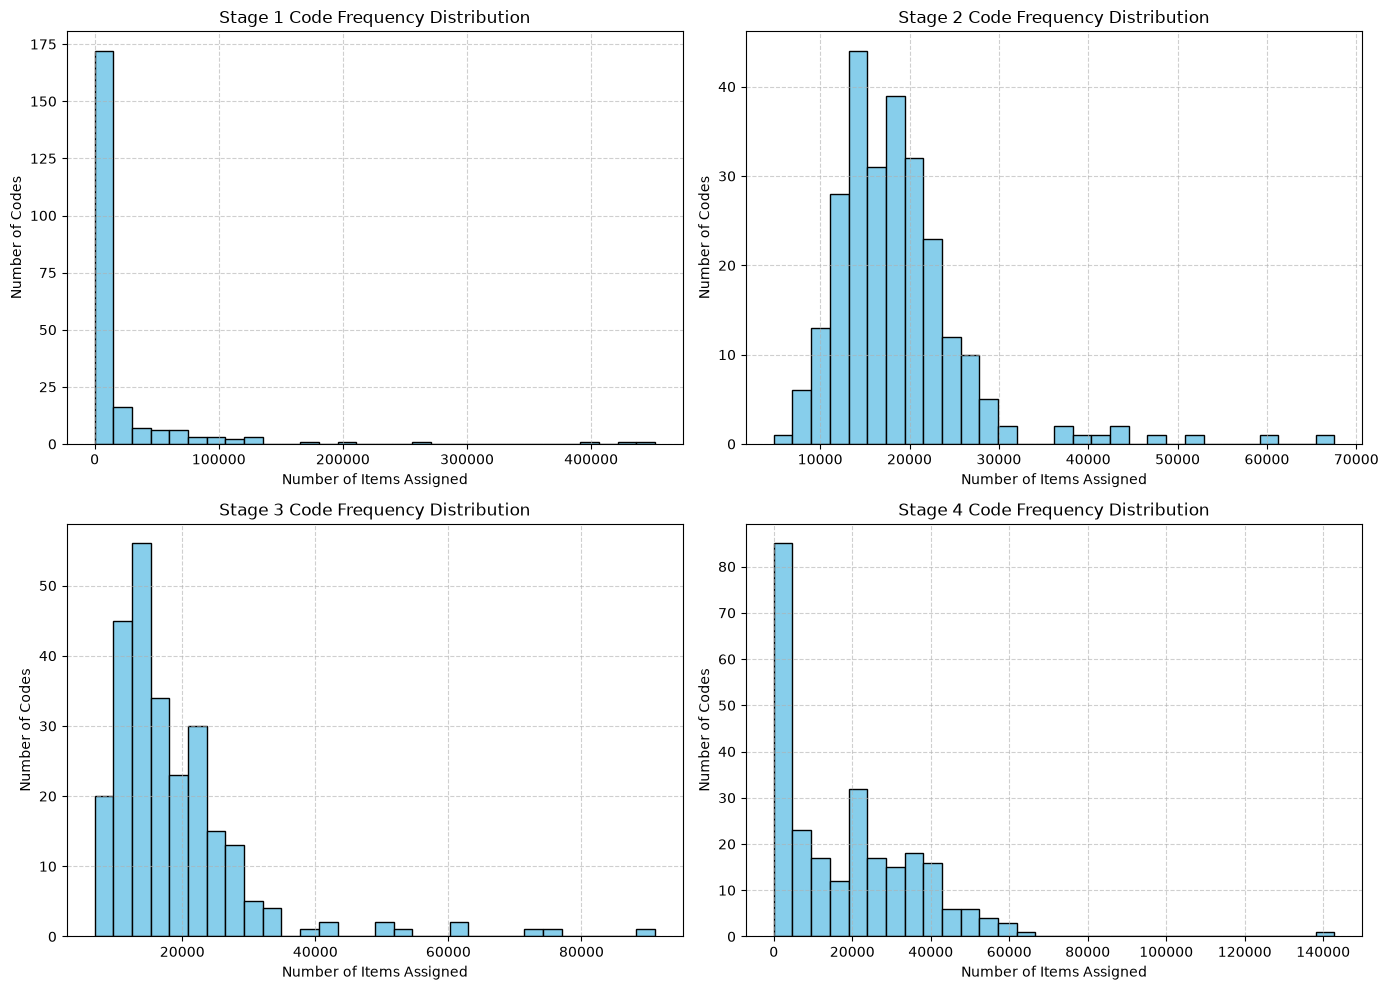

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for stage_idx in range(num_stages):
    stage_col = df.columns[stage_idx]
    counts = df[stage_col].value_counts()
    
    axes[stage_idx].hist(counts, bins=30, color='skyblue', edgecolor='black')
    axes[stage_idx].set_title(f'Stage {stage_idx + 1} Code Frequency Distribution')
    axes[stage_idx].set_xlabel('Number of Items Assigned')
    axes[stage_idx].set_ylabel('Number of Codes')
    axes[stage_idx].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

# Code Utilization Heatmap

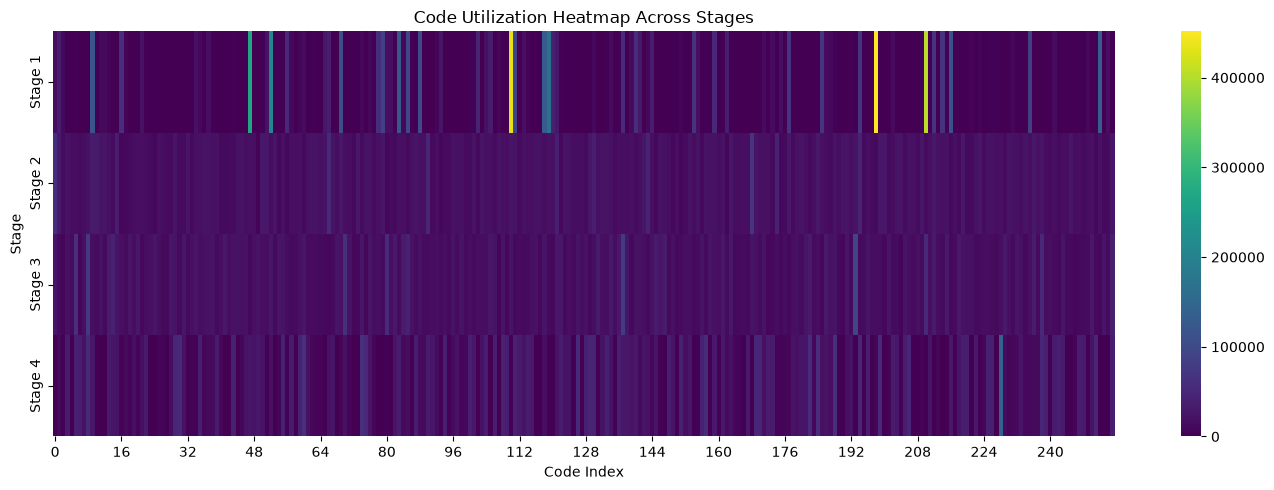

In [5]:
# Create a matrix of shape (num_stages, num_codes)
utilization_matrix = np.zeros((num_stages, num_codes))

for stage_idx in range(num_stages):
    stage_col = df.columns[stage_idx]
    counts = df[stage_col].value_counts()
    for code, count in counts.items():
        if 0 <= int(code) < num_codes:
            utilization_matrix[stage_idx, int(code)] = count

plt.figure(figsize=(14, 5))
sns.heatmap(utilization_matrix, cmap='viridis', cbar=True, 
            xticklabels=max(1, num_codes // 16), 
            yticklabels=[f'Stage {i+1}' for i in range(num_stages)])
plt.title('Code Utilization Heatmap Across Stages')
plt.xlabel('Code Index')
plt.ylabel('Stage')
plt.tight_layout()
plt.show()

# Prefix Growth Chart

--- SID Structure Metrics ---


,Total Items,Unique Full SIDs,Duplicate SID Rate,Depth 1,Depth 2,Depth 3,Depth 4
0,4783154,1823210,61.88%,224,21234,498147,1823210


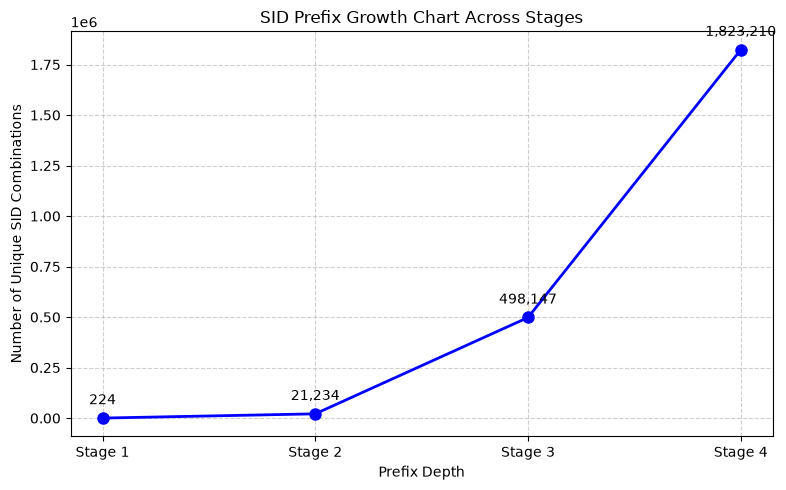

In [6]:
total_items = len(df)
num_stages_catalog = df.shape[1]

# Convert DataFrame to a NumPy array for fast operations
data_arr = df.to_numpy()

# 1. Calculate unique full SIDs and duplicate rate using structured view (much faster than apply)
# Convert rows to structured array bytes to quickly find unique items
struct_arr = np.ascontiguousarray(data_arr).view(np.dtype((np.void, data_arr.dtype.itemsize * data_arr.shape[1])))
unique_full_sids = len(np.unique(struct_arr))
duplicate_sid_rate = 1.0 - (unique_full_sids / total_items)

# 2. Calculate unique prefixes efficiently stage by stage
prefix_counts = []
for depth in range(1, num_stages_catalog + 1):
    sub_arr = data_arr[:, :depth]
    sub_struct = np.ascontiguousarray(sub_sub := sub_arr).view(np.dtype((np.void, sub_arr.dtype.itemsize * sub_arr.shape[1])))
    unique_prefixes = len(np.unique(sub_struct))
    
    prefix_counts.append({
        'Depth': f'Depth {depth}',
        'Unique Prefixes': unique_prefixes
    })

# Summary DataFrame
sid_metrics = {
    'Total Items': total_items,
    'Unique Full SIDs': unique_full_sids,
    'Duplicate SID Rate': f"{duplicate_sid_rate * 100:.2f}%",
}
for p in prefix_counts:
    sid_metrics[p['Depth']] = p['Unique Prefixes']

sid_metrics_df = pd.DataFrame([sid_metrics])
print("--- SID Structure Metrics ---")
display(sid_metrics_df)

# 3. Prefix Growth Chart Visualization
depths = [f'Stage {i}' for i in range(1, num_stages_catalog + 1)]
unique_values = [p['Unique Prefixes'] for p in prefix_counts]

plt.figure(figsize=(8, 5))
plt.plot(depths, unique_values, marker='o', linestyle='-', color='b', linewidth=2, markersize=8)
plt.title('SID Prefix Growth Chart Across Stages')
plt.xlabel('Prefix Depth')
plt.ylabel('Number of Unique SID Combinations')
plt.grid(True, linestyle='--', alpha=0.6)

for i, txt in enumerate(unique_values):
    plt.annotate(f"{txt:,}", (depths[i], unique_values[i]), textcoords="offset points", xytext=(0,10), ha='center')

plt.tight_layout()
plt.show()

Embeddings plot (Geometric Allignment & Semantic Structure)

In [ ]:
# ==========================================
# Load a Random Subset of K Item Embeddings via PyArrow
# ==========================================
import pyarrow.dataset as ds
import numpy as np
import pandas as pd

parquet_path = './local/2026-13-10-1-ei/item_embeddings.parquet'
K = 500000  # Number of random items you want to load

# 1. Load dataset metadata without loading all data into memory
dataset = ds.dataset(parquet_path, format="parquet")
total_rows = dataset.count_rows()

# 2. Generate K unique random row indices to sample
sampled_indices = np.random.choice(total_rows, size=min(K, total_rows), replace=False)
sampled_indices.sort()  # Sorting speeds up reading from disk sequentially

# 3. Use PyArrow to take/filter only the specific rows
# (Note: dataset.take() accepts row indices efficiently)
table = dataset.take(sampled_indices)

# 4. Extract columns directly
item_ids = table.column('item_id').to_numpy()
embeddings_list = table.column('embedding').to_numpy()

# Create a temporary DataFrame aligned with the subset
embeddings_df = pd.DataFrame({
    'embedding': embeddings_list
}, index=item_ids)

# Align with your main dataframe subset if needed
# (Ensure your `df` also filters to these item IDs if matching them)
embeddings_matrix = np.vstack(embeddings_df['embedding'].values)

print(f"Loaded a random subset of shape: {embeddings_matrix.shape}")
print(f"Is embedding_df subset of df {set(embeddings_df.index).issubset(set(df.index))}")

Loaded a random subset of shape: (500000, 256)


AttributeError: 'numpy.ndarray' object has no attribute 'index'

# SID vs Embedding Similarity Plot

C:\Users\justin\AppData\Local\Temp\ipykernel_25980\460560153.py:43: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=matching_prefixes, y=pair_cos_sims, palette="Blues", showfliers=False)


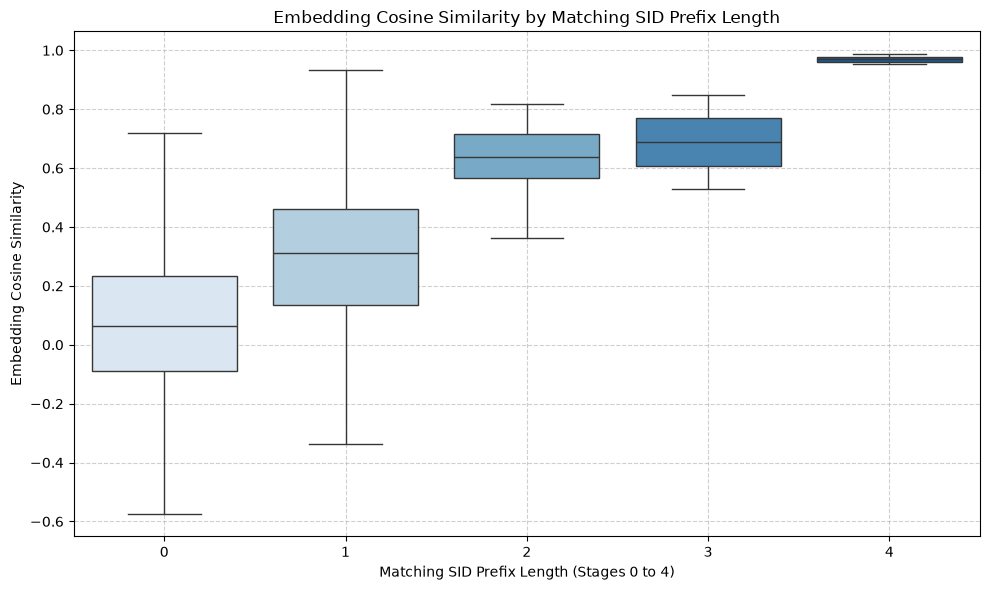

In [9]:
# ==========================================
# A. SID Similarity vs. Embedding Similarity Plot
# ==========================================
import random
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Extract SIDs for the exact items present in our loaded embedding subset
sub_sid_df = df.loc[embeddings_df.index]
sid_tuples = [tuple(x) for x in sub_sid_df.to_numpy()]

# 2. Pre-normalize embeddings for lightning-fast cosine similarity (via dot product)
norms = np.linalg.norm(embeddings_matrix, axis=1, keepdims=True)
norm_embeddings = embeddings_matrix / (norms + 1e-8)

# 3. Sample random pairs from the subset (e.g., 50,000 pairs)
num_pairs_to_sample = 50000
K_subset = len(embeddings_matrix)

pair_cos_sims = []
matching_prefixes = []

for _ in range(num_pairs_to_sample):
    i, j = random.sample(range(K_subset), 2)
    
    # Fast cosine similarity (since vectors are L2-normalized)
    cos_sim = np.dot(norm_embeddings[i], norm_embeddings[j])
    
    # Calculate matching prefix length (how many sequential stages match)
    s1, s2 = sid_tuples[i], sid_tuples[j]
    match_len = 0
    for t1, t2 in zip(s1, s2):
        if t1 == t2:
            match_len += 1
        else:
            break
            
    pair_cos_sims.append(cos_sim)
    matching_prefixes.append(match_len)

# 4. Plotting using a clean Boxplot (hiding outlier fliers for a cleaner view)
plt.figure(figsize=(10, 6))
sns.boxplot(x=matching_prefixes, y=pair_cos_sims, palette="Blues", showfliers=False)

plt.title('Embedding Cosine Similarity by Matching SID Prefix Length')
plt.xlabel('Matching SID Prefix Length (Stages 0 to 4)')
plt.ylabel('Embedding Cosine Similarity')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# Umap of Item Embeddings Colored by First-Stage Code

Running UMAP dimensionality reduction (this may take a minute)...


c:\Users\justin\Documents\GitHub\NZ5-GR\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


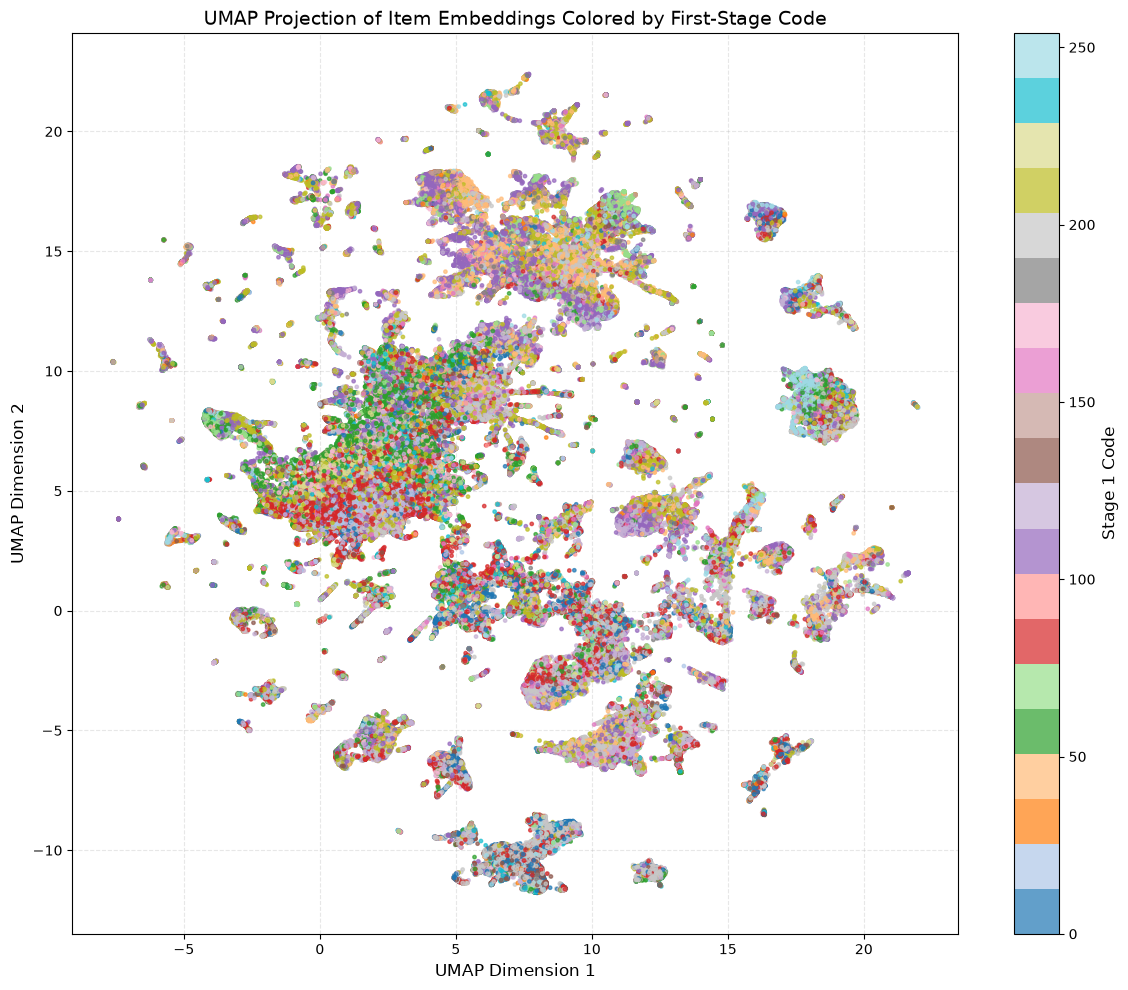

In [11]:
# ==========================================
# B. UMAP of Item Embeddings Colored by First-Stage Code
# ==========================================
import matplotlib.pyplot as plt
import numpy as np
import umap

# 1. Extract the Stage 1 code (column 0) for your sampled items
stage1_codes = df.loc[embeddings_df.index, 0].values

# 2. Run UMAP dimensionality reduction
print("Running UMAP dimensionality reduction (this may take a minute)...")
reducer = umap.UMAP(n_components=2, random_state=42, n_neighbors=15, min_dist=0.1)
embedding_2d = reducer.fit_transform(embeddings_matrix)

# 3. Plotting the 2D projection colored by Stage 1 code
plt.figure(figsize=(12, 10))
scatter = plt.scatter(
    embedding_2d[:, 0], 
    embedding_2d[:, 1], 
    c=stage1_codes, 
    cmap='tab20', 
    s=6, 
    alpha=0.7
)
cbar = plt.colorbar(scatter)
cbar.set_label('Stage 1 Code', fontsize=12)

plt.title('UMAP Projection of Item Embeddings Colored by First-Stage Code', fontsize=14)
plt.xlabel('UMAP Dimension 1', fontsize=12)
plt.ylabel('UMAP Dimension 2', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

In [12]:
# ==========================================
# C. Nearest-Neighbor Preservation via Faiss
# ==========================================
import faiss
import numpy as np

# 1. Ensure embeddings are float32 and L2-normalized for cosine similarity
norm_embeddings = embeddings_matrix.astype('float32')
faiss.normalize_L2(norm_embeddings)

# 2. Build a fast exact inner-product index in Faiss
d = norm_embeddings.shape[1]
index = faiss.IndexFlatIP(d)
index.add(norm_embeddings)

# 3. Query top-K+1 nearest neighbors for all items in the subset
# (k=11 because the closest neighbor to an item is itself, which we will exclude)
K_neighbors = 10
print(f"Running Faiss search for {len(norm_embeddings)} items...")
distances, neighbor_indices = index.search(norm_embeddings, K_neighbors + 1)

# 4. Extract SIDs for the subset
sub_sid_df = df.loc[embeddings_df.index]
sid_array = sub_sid_df.to_numpy()

# 5. Calculate prefix overlap rates against true vector neighbors
preservation_stats = {1: 0, 2: 0, 3: 0, 4: 0}
total_checked = 0

for i in range(len(norm_embeddings)):
    q_sid = sid_array[i]
    # Exclude the first index since it's the item itself (distance ~ 1.0)
    true_neighbors = neighbor_indices[i][1:]
    
    for n_idx in true_neighbors:
        n_sid = sid_array[n_idx]
        
        # Count matching sequential prefix stages
        match_len = 0
        for s1, s2 in zip(q_sid, n_sid):
            if s1 == s2:
                match_len += 1
            else:
                break
        
        for stage in range(1, 5):
            if match_len >= stage:
                preservation_stats[stage] += 1
        total_checked += 1

# 6. Print final preservation percentages
print("\n--- Nearest-Neighbor Prefix Preservation Rates ---")
for stage in range(1, 5):
    rate = (preservation_stats[stage] / total_checked) * 100
    print(f"At least {stage}-stage prefix match: {rate:.2f}% of true neighbors")

Running Faiss search for 500000 items...

--- Nearest-Neighbor Prefix Preservation Rates ---
At least 1-stage prefix match: 34.72% of true neighbors
At least 2-stage prefix match: 21.31% of true neighbors
At least 3-stage prefix match: 9.40% of true neighbors
At least 4-stage prefix match: 3.90% of true neighbors
